## Import Libraries


In [ ]:
import tensorflow
import keras
from keras.datasets import mnist
from matplotlib import pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,UpSampling2D

## Data Collection and understanding

In [ ]:
(X_train,_),(X_test,_) = mnist.load_data()

X_train.shape, X_test.shape

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


((60000, 28, 28), (10000, 28, 28))

## Data Preparation

### Rescale/Resize the image

In [ ]:
X_train = X_train.reshape(60000, 28, 28, 1)
X_test = X_test.reshape(10000, 28, 28, 1)

X_train.shape, X_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

### Normalize the image

In [ ]:
X_train = X_train/255.0
X_test = X_test/255.0

X_train.min(),X_train.max()

(np.float64(0.0), np.float64(1.0))

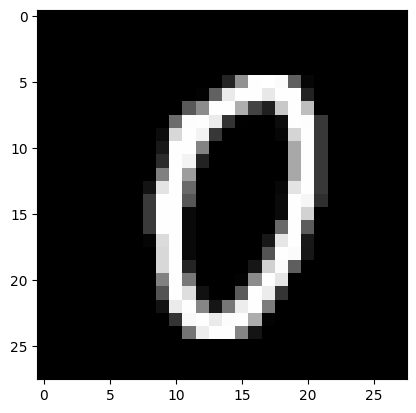

In [ ]:
plt.imshow(X_train[1000], cmap="grey")

### Apply noise to this data

In [ ]:
X_train_noise = X_train + 0.2 * np.random.normal(loc=0.0, scale=1.0, size= X_train.shape)
X_test_noise = X_test + 0.2 * np.random.normal(loc=0.0, scale=1.0, size= X_test.shape)

X_train_noise.min(),X_train_noise.max()

(np.float64(-1.164167714245684), np.float64(2.0333186652092223))

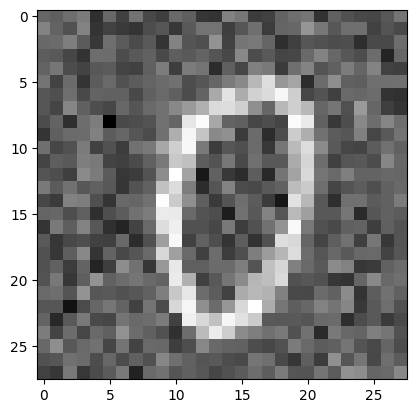

In [ ]:
plt.imshow(X_train_noise[1000], cmap="grey")

In [ ]:
## Having only positive values and removing the negative pixels

X_train_clipped = np.clip(a=X_train_noise, a_min=0, a_max=1.)
X_test_clipped = np.clip(a=X_test_noise, a_min=0, a_max=1.)

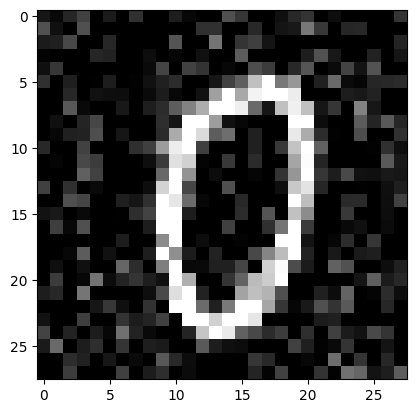

In [ ]:
plt.imshow(X_train_clipped[1000], cmap="grey")

## Model Building

In [ ]:
model = Sequential()


## Encoding

model.add(Conv2D(32, kernel_size=(3,3),strides=(1,1),activation="relu",padding="same",input_shape= (28,28,1)))
model.add(MaxPool2D((2,2)))
model.add(Conv2D(16, kernel_size=(3,3),strides=(1,1),activation="relu",padding="same"))
model.add(MaxPool2D((2,2)))

## Decoding

model.add(Conv2D(16, kernel_size=(3,3),strides=(1,1),activation="relu",padding="same"))
model.add(UpSampling2D((2,2)))
model.add(Conv2D(32, kernel_size=(3,3),strides=(1,1),activation="relu",padding="same"))
model.add(UpSampling2D((2,2)))
model.add(Conv2D(1, kernel_size=(3,3), activation="relu", padding="same"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_48 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_17 (UpSampling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",loss="mean_squared_error",metrics=["Accuracy"])

In [ ]:
model.fit(X_train_clipped,X_train,batch_size=32,epochs=10,validation_data=(X_test_clipped,X_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - Accuracy: 0.8143 - loss: 0.0091 - val_Accuracy: 0.8140 - val_loss: 0.0057
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Accuracy: 0.8151 - loss: 0.0054 - val_Accuracy: 0.8142 - val_loss: 0.0049
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Accuracy: 0.8152 - loss: 0.0048 - val_Accuracy: 0.8142 - val_loss: 0.0045
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Accuracy: 0.8152 - loss: 0.0045 - val_Accuracy: 0.8143 - val_loss: 0.0043
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Accuracy: 0.8153 - loss: 0.0043 - val_Accuracy: 0.8143 - val_loss: 0.0042
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Accuracy: 0.8153 - loss: 0.0042 - val_Accuracy: 0.8143 - val_loss: 0.0041
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Accuracy: 0.8153 - loss: 0.0041 - val_Accuracy: 0.8143 - val_loss: 0.0040
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Accuracy: 0.8153 - loss: 0.0040 -

## Model Evalutaion and Testing

In [ ]:
model.evaluate(X_test_clipped,X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8143 - loss: 0.0038


[0.0038323875050991774, 0.814324140548706]

In [ ]:
y_pred = model.predict(X_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [ ]:
model.save("Auto_encoder.h5")